# Notebook to build the script of Circonscription Map generation

## For 28th of November
1. project France Metropol map from INSEE in EPSG:2154
2. Perform Correction, check, and simplify_coverage
3. Check Size of file
4. Append with SciencePo Service Map (Only COM)
5. Project result in EPSG:4326
6. Append DROM
7. Check few cases (at borders of circo)
8. check size of file

# Retrieve Map from INSEE

In [104]:
import requests, geopandas as gpd

url = "https://www.data.gouv.fr/api/1/datasets/r/dbf42fce-a563-412e-9db1-1f7ab453c2ef"
r = requests.get(url)
#read zip file content into a GeoDataFrame
gpf_insee = gpd.read_file(r.content)
#return 5 first rows of the GeoDataFrame
gpf_insee.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."


In [105]:
# check the Coordinate Reference System (CRS) of the GeoDataFrame
gpf_insee.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
gpf_insee.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  558 non-null    str     
 1   dep       558 non-null    str     
 2   libelle   558 non-null    str     
 3   geometry  558 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 37.7 KB


## Filter out DROM circo

Since we are going to project the coordinate we will focus on France Mainland and Corsica to avoid distortion on DROM territories

In [109]:
#select only metropolitan circo
gpf_insee_metro = gpf_insee.query('dep not in ("976","974","971","972","973")')
gpf_insee_metro.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 539 entries, 19 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  539 non-null    str     
 1   dep       539 non-null    str     
 2   libelle   539 non-null    str     
 3   geometry  539 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 36.6 KB


## Simplify Map drawing to reduce Map size

### 1. convert CRS from EPSG:4326 to EPSG:2154 (RGF93 / Lambert-93) : metre based system and standard for France

Only Metropolitan France will be converted

Select Metropolitan France for projection to Lambert-93

In [147]:
gpf_insee_metro_2154 = gpf_insee_metro.to_crs(epsg=2154)
gpf_insee_metro_2154.head(5)

,id_circo,dep,libelle,geometry
19,3803,38,Isère - 3e circonscription,"MULTIPOLYGON (((912109.954 6457923.04, 912109...."
20,3801,38,Isère - 1re circonscription,"MULTIPOLYGON (((915462.964 6455639.971, 915432..."
21,3810,38,Isère - 10e circonscription,"MULTIPOLYGON (((908663.001 6490151.051, 908295..."
22,3804,38,Isère - 4e circonscription,"MULTIPOLYGON (((921862.979 6404787.053, 919770..."
23,3802,38,Isère - 2e circonscription,"MULTIPOLYGON (((925974.023 6448347.016, 926533..."


### 2. We test wether the geometry is valid

First we check if the coverage is valid

In [148]:
gpf_insee_metro_2154.geometry.is_valid_coverage(gap_width=10)

False

We diagnose what the problem is

In [149]:
coverage_pb_type = gpf_insee_metro_2154.invalid_coverage_edges().geom_type[gpf_insee_metro_2154.invalid_coverage_edges().count_geometries() != 1].unique()
# the ','.join(map(str,a)) will print all elements of the list above separated by comma
print(f'problem of coverage (over-lapping polygons or mismatched edges) detected in the geodataframes are of type {','.join(map(str,coverage_pb_type))}')

problem of coverage (over-lapping polygons or mismatched edges) detected in the geodataframes are of type MultiLineString


We test the polygons individually. It is essential for the simplification.

In [154]:
# return all rows with a result different than "valid geometry"
df_errors = gpf_insee_metro_2154.geometry.is_valid_reason()[gpf_insee_metro_2154.geometry.is_valid_reason() != "Valid Geometry"]
# retrieve first part of the message and return unique values
errors_type = df_errors.str.split(pat="[",expand=True)[0].unique()
print(errors_type)

<ArrowStringArray>
[                   'Self-intersection',
 'Too few points in geometry component',
                        'Nested shells',
               'Ring Self-intersection',
              'Hole lies outside shell']
Length: 5, dtype: str


In [155]:
df_errors [df_errors.str.split(pat="[",expand=True)[0] == "Hole lies outside shell"]

84     Hole lies outside shell[698131.076061191 70624...
102    Hole lies outside shell[694909.356802225 69239...
dtype: str

plot to test the "Hole lies outsed shell" error

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

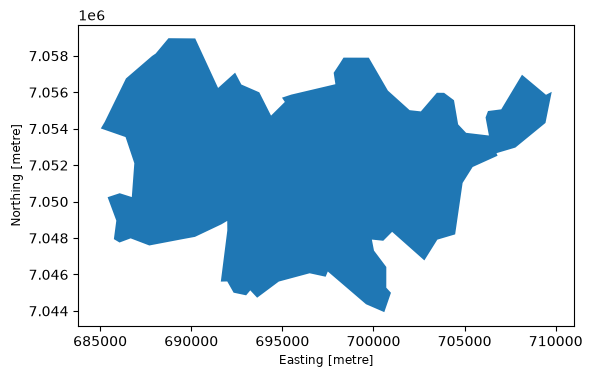

In [153]:
gpf_insee_metro_2154.iloc[[84]].plot()

### 3. We repair the polygons individually
 
Function to repair and normalize the type of geometry -> transform Geometry Collection into Polygons and Multipolygons

Then a function to test if the area has not been modified too much by the repairs.

The source of the functions is https://www.geospatialdatatesting.org/spatial-test-pattern-design-implementation/geometry-validation-patterns/repairing-invalid-geometries-with-make-valid-safely/

In [120]:
from shapely import make_valid
from shapely.geometry import MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry


def repair_polygonal(geom: BaseGeometry) -> BaseGeometry:
    """make_valid, then keep only the polygonal parts of the result."""
    if geom.is_valid:
        return geom

    fixed = make_valid(geom)

    if fixed.geom_type == "GeometryCollection":
        parts = [g for g in fixed.geoms if g.geom_type in ("Polygon", "MultiPolygon")]
        if not parts:
            raise ValueError("repair produced no polygonal geometry")
        fixed = parts[0] if len(parts) == 1 else MultiPolygon(
            [p for g in parts for p in (g.geoms if g.geom_type == "MultiPolygon" else [g])]
        )
    if fixed.is_empty:
        raise ValueError("repair produced an empty geometry")
    return fixed

In [158]:
AREA_TOLERANCE = 2e-9       # relative, this tolerance has been chosen by increasing progressively the value proposed by the source (1e-9)


def repair_with_area_check(geom: BaseGeometry, tol: float = AREA_TOLERANCE):
    before = geom.area
    fixed = repair_polygonal(geom)
    after = fixed.area

    if before > 0:
        drift = abs(after - before) / before
        if drift > tol:
            raise ValueError(
                f"repair changed area by {drift:.2%} "
                f"({before:.6f} -> {after:.6f})"
            )
    return fixed

apply function

In [159]:
#copy of the geodataframe to apply repair function and area comparison
gpf_insee_metro_2154_fixed = gpf_insee_metro_2154.copy()
gpf_insee_metro_2154_fixed.geometry = gpf_insee_metro_2154.geometry.apply(repair_with_area_check)

In [221]:
# return all rows with a result different than "valid geometry"
df_errors = gpf_insee_metro_2154_fixed.geometry.is_valid_reason()[gpf_insee_metro_2154_fixed.geometry.is_valid_reason() != "Valid Geometry"]
if df_errors.empty : 
    print("no unvalid geometries")

no unvalid geometries


### 4. Repair coverage

First we estimate size of max overlap and max of gap distances, then we correct gaps and overlaps

First we test if the coverage is valid after polygons repair

In [161]:
gpf_insee_metro_2154_fixed.geometry.is_valid_coverage(gap_width=10)

False

function to get the order of magnitude of max overlap

In [163]:
from shapely import maximum_inscribed_circle

def max_overlap_width(geom: BaseGeometry) :
    """return the diameter of the largest circles that fit in the intersection of polygons"""

    # 1. Self-join to find overlapping pairs
    overlaps = gpd.overlay(geom, geom, how="intersection", keep_geom_type=True)

    # Filter out self-intersections (assuming a unique 'id' column, or use index)
    geom["temp_id"] = geom.index
    overlaps = gpd.overlay(geom, geom, how="intersection")
    overlaps = overlaps[overlaps["temp_id_1"] < overlaps["temp_id_2"]]

    # 2. Calculate max width (diameter of largest inscribed circle)
    if not overlaps.empty:
        # maximum_inscribed_circle returns a LineString from center to boundary (length = radius)
        overlaps["max_width"] = overlaps.geometry.apply(
            lambda geom: maximum_inscribed_circle(geom).length * 2
        )
        max_overlap_width = overlaps["max_width"].max()
    else:
        max_overlap_width = 0.0

    print(f"Max overlap width: {max_overlap_width:.2f}")

    return overlaps

In [164]:
gpf_overlap = max_overlap_width(gpf_insee_metro_2154_fixed)

/Users/pierremoneyron/anaconda3/lib/python3.14/site-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 4194 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


Max overlap width: 52.65


We can visualize the overlap

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

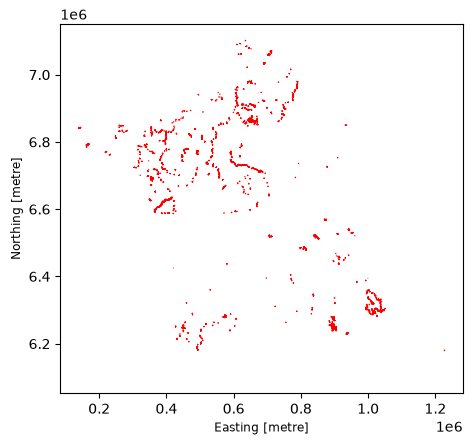

In [170]:
gpf_overlap.plot(edgecolor="red", linewidth=1)

In [225]:
from shapely.geometry import Polygon

def max_gap_width(geom= BaseGeometry):
    # 1. Merge all polygons into one
    dissolved = geom.union_all()

    # 2. Extract interior holes as individual Polygons
    gaps = []
    geoms = [dissolved] if dissolved.geom_type == "Polygon" else dissolved.geoms

    for poly in geoms:
        for interior in poly.interiors:
            gaps.append(Polygon(interior))

    gaps_gdf = gpd.GeoDataFrame(geometry=gaps, crs=geom.crs)

    # 3. Calculate max width of the gaps
    if not gaps_gdf.empty:
        gaps_gdf["max_width"] = gaps_gdf.geometry.apply(
            lambda geom: maximum_inscribed_circle(geom).length * 2
        )
        max_gap_width = gaps_gdf["max_width"].max()
    else:
        max_gap_width = 0.0
    print(f"Max gap width: {max_gap_width:.2f}")

    return gaps_gdf

In [226]:
gpf_gaps = max_gap_width(gpf_insee_metro_2154_fixed)

Max gap width: 2732.85


We can visualize the gaps

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

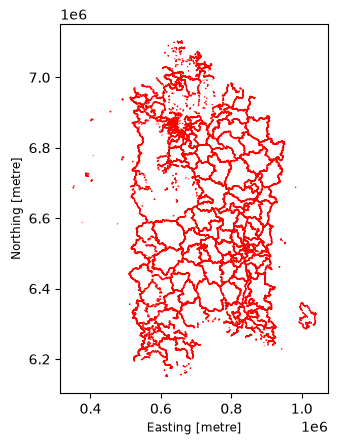

In [227]:
gpf_gaps.plot(edgecolor="red", linewidth=1)

Attempt to correct overlapping. Considering Max overlap is about 53m and max gap is about 2750 we will use a snappping_distance 2.0 (avoid over simplify the edges) and a gap_width=0.0 (as a far as possible from 2750)

In [177]:
from shapely import coverage_clean
gpf_insee_metro_2154_fixed_no_overlaps = gpf_insee_metro_2154_fixed.copy()

gpf_insee_metro_2154_fixed_no_overlaps.geometry = coverage_clean(
    gpf_insee_metro_2154_fixed.geometry.values,
    gap_width=0.0,
    snapping_distance=2.0,
    merge_strategy="longest_border"
)

Let's check the max overlap distance after correction

In [178]:
max_overlap_width(gpf_insee_metro_2154_fixed_no_overlaps)

Max overlap width: 0.00


/Users/pierremoneyron/anaconda3/lib/python3.14/site-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 2924 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


,id_circo_1,dep_1,libelle_1,temp_id_1,id_circo_2,dep_2,libelle_2,temp_id_2,geometry


attempt to correct gaps, this time we choose a gap_width of 2750m to capture all gaps

In [181]:
gpf_insee_metro_2154_fixed_no_gaps = gpf_insee_metro_2154_fixed_no_overlaps.copy()
gpf_insee_metro_2154_fixed_no_gaps.geometry = coverage_clean (
    gpf_insee_metro_2154_fixed_no_overlaps.geometry.values,
    gap_width=2750.0,
    snapping_distance=2.0,
    merge_strategy="longest_border"
)

In [182]:
max_gap_width(gpf_insee_metro_2154_fixed_no_gaps)

Max gap width: 0.00


,geometry


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

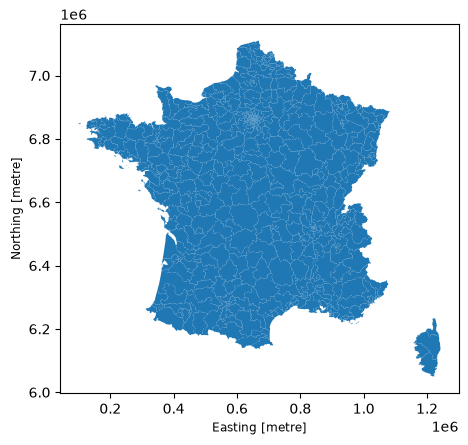

In [183]:
gpf_insee_metro_2154_fixed_no_gaps.plot()

We can now check if the coverage is valid

In [184]:
gpf_insee_metro_2154_fixed_no_gaps.is_valid_coverage()

True

### 5. Apply simply geometry
First we use the lowest value possible of tolerance to keep the map as precise as possible

In [212]:
gpf_insee_metro_2154_simplified = gpf_insee_metro_2154_fixed_no_gaps.copy()
gpf_insee_metro_2154_simplified = gpf_insee_metro_2154_simplified.simplify_coverage(tolerance=1)

check validity of coverage

In [229]:
gpf_insee_metro_2154_simplified.is_valid_coverage()

True

### 6. Check size of file (Mainland and Corsica only, in EPSG:2154)

Function to test size of a geodataframe written in geoJSON

In [210]:
gpf_insee_metro_2154_simplified.info()

<class 'geopandas.geoseries.GeoSeries'>
RangeIndex: 539 entries, 19 to 557
Series name: None
Non-Null Count  Dtype   
--------------  -----   
539 non-null    geometry
dtypes: geometry(1)
memory usage: 4.3 KB


In [216]:
import os
gpf_insee_metro_2154_simplified.to_file("test_size.geojson",driver="GeoJSON")
print(f"size is {round(os.path.getsize("test_size.geojson")/(1024*1024),1)} MB")
os.remove("test_size.geojson")

size is 6.2 MB


### Tests few cases at circonscription border

# Retrieve COM (Communes D'Outre Mer) from ArcGIS Science PO service

### Download map of COM from Science PO service and change CRS (Coordinate Reference System)

# Concat Maps

## Export File to designated folder